In [1]:
import pandas as pd

In [3]:
df = pd.read_csv('Data/creditcard.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
df.shape

(284807, 31)

In [ ]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [15]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
284802    False
284803    False
284804    False
284805    False
284806    False
Length: 284807, dtype: bool

## Visualization

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

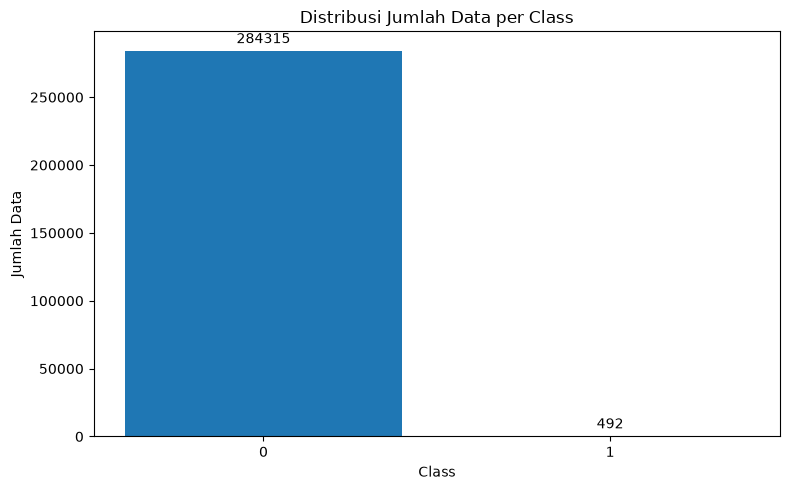

In [23]:
jumlah = df['Class'].value_counts().sort_index()
plt.figure(figsize=(8, 5))
bars = plt.bar(jumlah.index.astype(str), jumlah.values)
plt.bar_label(bars, padding=3)
plt.title('Distribusi Jumlah Data per Class')
plt.xlabel('Class')
plt.ylabel('Jumlah Data')
plt.tight_layout()
plt.show()

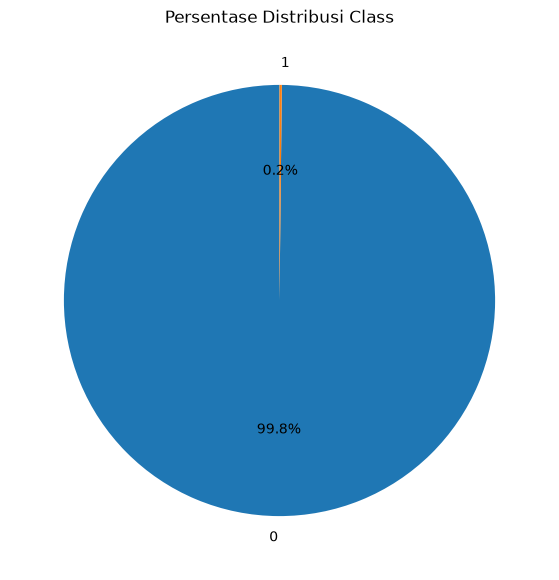

In [18]:
plt.figure(figsize=(7, 7))
plt.pie(
    jumlah.values,
    labels=jumlah.index.astype(str),
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Persentase Distribusi Class')
plt.show()

In [24]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE 

In [26]:
x = df.drop(columns='Class')
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Resampling Method

In [29]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

from imblearn.over_sampling import (
    RandomOverSampler,
    SMOTE,
    ADASYN,
    BorderlineSMOTE
)

from imblearn.under_sampling import RandomUnderSampler,NearMiss

from imblearn.combine import SMOTEENN,SMOTETomek

In [28]:
resampling_methods = {
    "No Resampling": None,

    "RandomOverSampler": RandomOverSampler(
        random_state=42
    ),

    "SMOTE": SMOTE(
        random_state=42
    ),

    "ADASYN": ADASYN(
        random_state=42
    ),

    "BorderlineSMOTE": BorderlineSMOTE(
        random_state=42
    ),

    "RandomUnderSampler": RandomUnderSampler(
        random_state=42
    ),

    "NearMiss": NearMiss(
        version=1
    ),

    "SMOTEENN": SMOTEENN(
        random_state=42
    ),

    "SMOTETomek": SMOTETomek(
        random_state=42
    )
}

## Modeling with RandomForestClassifier and GradientBoostingCLassifier

In [30]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [31]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

In [32]:
results = []
trained_models = {}

for model_name, model_template in models.items():

    for sampling_name, sampler in resampling_methods.items():

        print(f"{model_name} | {sampling_name}")

        # Resampling hanya pada training set
        if sampler is None:
            X_resampled, y_resampled = X_train, y_train
        else:
            X_resampled, y_resampled = sampler.fit_resample(
                X_train, y_train
            )

        # Salin model agar tiap eksperimen independen
        from sklearn.base import clone
        model = clone(model_template)

        model.fit(X_resampled, y_resampled)

        # Prediksi pada test set asli
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        results.append({
            "Model": model_name,
            "Resampling": sampling_name,
            "Train Samples": len(y_resampled),
            "Precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred, zero_division=0
            ),
            "F1-Score": f1_score(
                y_test, y_pred, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
            "PR-AUC": average_precision_score(y_test, y_prob)
        })

        trained_models[(model_name, sampling_name)] = model

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="F1-Score", ascending=False
).round(4)


Random Forest | No Resampling
Random Forest | RandomOverSampler
Random Forest | SMOTE
Random Forest | ADASYN
Random Forest | BorderlineSMOTE
Random Forest | RandomUnderSampler
Random Forest | NearMiss
Random Forest | SMOTEENN
Random Forest | SMOTETomek
Gradient Boosting | No Resampling
Gradient Boosting | RandomOverSampler
Gradient Boosting | SMOTE
Gradient Boosting | ADASYN
Gradient Boosting | BorderlineSMOTE


KeyboardInterrupt: 

In [ ]:
for metric in ["F1-Score", "Recall", "PR-AUC"]:
    pivot = results_df.pivot(
        index="Resampling",
        columns="Model",
        values=metric
    )

    ax = pivot.plot(kind="bar", figsize=(12, 5))

    ax.set_title(f"Perbandingan Random Forest vs Gradient Boosting — {metric}")
    ax.set_xlabel("Metode Resampling")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=40)
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()